In [1]:
MODEL_CODE = "dt"
MODEL_NAME = "Decision Tree"

# 07: Decision Tree Modeli

**Proje:** Framingham Kalp Çalışması verisi ile inme (stroke) tahmini · **Model ailesi:** ağaç / bagging

**Decision Tree**, veriyi "AGE > 60 mı?", "SYSBP > 150 mi?" gibi evet/hayır sorularıyla tekrar tekrar ikiye böler ve her yaprakta bir karar verir. Kararı bir soru dizisi olduğu için doğrudan okunabilen bir modeldir. Sınır verilmezse her yaprakta tek bir sınıf kalana kadar böler ve eğitim verisini ezberler (overfitting); bu yüzden ağacın boyu hiperparametrelerle sınırlanır.

**Model neyi kendisi öğrenir, neyi biz seçeriz?** Hangi sütunda hangi eşikle bölüneceğini model eğitim sırasında kendisi bulur. Ağacın ne kadar derinleşeceği, bir yaprakta en az kaç kişi kalacağı ve dengesizliğin nasıl giderileceği ise eğitimden önce verilmesi gereken ayarlardır (hiperparametre). Bunlar GridSearch ile tüm kombinasyonlar denenerek, ortak CV katları üzerinde seçilir.

**Bu notebook'ta yapılanlar:** hiperparametre ve dengeleme araması · derinliğin overfitting'e etkisi · feature engineering'in etkisi · final modelin CV değerlendirmesi, eşik seçimi, öğrenme eğrisi · ağacın ilk seviyeleri · test seti · XAI (SHAP, yakalanan ve kaçırılan hasta için LIME) · özellik çıkarma

**Colab'da çalıştırmak için:** Sol menüdeki klasör simgesinden `train.csv`, `test.csv`, `config.py`, `preprocessing.py`, `metrics.py` ve `explain.py` dosyalarını yükleyin.

## 1. Kurulum

In [2]:
# shap and lime are not preinstalled on Colab
try:
    import lime
    import shap
except ImportError:
    %pip install -q shap lime

/Users/Sude/Documents/GitHub/stroke_detection_ML/test/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
import sys
from pathlib import Path

# Repo: ../src. Colab: the src/*.py files uploaded to the working directory.
SRC_DIR = next((p for p in (Path("../src"), Path("src"), Path(".")) if (p / "config.py").exists()), None)
if SRC_DIR is None:
    raise FileNotFoundError("config.py bulunamadı. Colab'da src klasöründeki .py dosyalarını sol menüden yükleyin.")
sys.path.insert(0, str(SRC_DIR.resolve()))

# Output folders: models/ and figures/ at the repo root (the working directory on Colab)
ROOT = SRC_DIR.resolve().parent if SRC_DIR.resolve().name == "src" else Path(".")
MODEL_DIR = ROOT / "models";  MODEL_DIR.mkdir(exist_ok=True)
FIG_DIR = ROOT / "figures";   FIG_DIR.mkdir(exist_ok=True)

import time
import warnings

import joblib
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from imblearn.over_sampling import SMOTE
from sklearn.metrics import average_precision_score
from sklearn.model_selection import GridSearchCV
from sklearn.tree import DecisionTreeClassifier, plot_tree

from config import CLASS_NAMES, MAIN_METRIC, RANDOM_STATE
from explain import explain, lime_local
from metrics import (SCORING, cv_evaluate, learning_curve_analysis, shared_cv, test_evaluate,
                     threshold_analysis)
from preprocessing import build_pipeline, load_data

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)

## 2. Veri

`train.csv` / `test.csv`. Ön işleme (feature engineering, encoding, ölçekleme, SMOTE) `build_pipeline()` içinde yapılır; test seti en sona kadar kullanılmaz.

In [4]:
X_train, X_test, y_train, y_test = load_data()
print("Eğitim:", X_train.shape, f"| inme: {y_train.sum()} kişi ({y_train.mean():.2%})")
print("Test:  ", X_test.shape, f"| inme: {y_test.sum()} kişi ({y_test.mean():.2%})")

Eğitim: (3521, 17) | inme: 306 kişi (8.69%)
Test:   (881, 17) | inme: 77 kişi (8.74%)


## 3. Hiperparametre ve dengeleme araması

Bu bölüm, final modelin ayarlarına adım adım nasıl varıldığını gösterir: önce hiçbir ayar yapılmamış **varsayılan model** ölçülür, sonra ayarlar aranır, sonra her ayarın tek başına etkisi tablo ve grafikle gösterilir. Seçim bir alışkanlığa değil, bu karşılaştırmalara dayanır.

| Parametre | Denenen değerler | Anlamı |
|---|---|---|
| `max_depth` | 2, 3, 4, 5, 6, 8, 10, None | Ağacın en fazla kaç seviye derinleşeceği. Derin ağaç eğitim verisine sıkı uyar (overfitting), `None` sınırsız demektir |
| `min_samples_leaf` | 1, 5, 10, 20, 40, 80, 120, 160, 240 | Bir yaprakta en az kaç kişi kalacağı. Büyük değer, tek tük hastaya özel kural öğrenilmesini engeller. İlk aramada en büyük değer 80'di ve seçilen değer buydu; aralık, optimumun kenarda kalıp kalmadığını görmek için 240'a kadar genişletildi |
| `criterion` | gini, entropy | Bölmenin iyiliğini ölçen formül |
| dengeleme | yok, SMOTE, class_weight | SMOTE azınlık sınıfı için sentetik hasta üretir. class_weight veri üretmez, inme vakalarındaki hatayı daha ağır cezalandırır. "Yok" kolu, dengelemenin gerçekten gerekli olup olmadığını gösteren referanstır |

Dengeleme de aramanın bir parçasıdır: SMOTE'lu satırlarda pipeline'ın `balance` adımı SMOTE, diğerlerinde bu adım boştur (`passthrough`); class_weight'li satırlarda ağaca `class_weight="balanced"` verilir. 3 × 9 × 8 × 2 = 432 kombinasyonun tamamı aynı CV katları (`shared_cv()`) ve aynı metriklerle (`SCORING`) karşılaştırılır; en iyi model `MAIN_METRIC` (PR-AUC) ile seçilir.

**Not (std):** Bu bölümdeki "± std" değerleri 5 katın PR-AUC'sinin standart sapmasıdır (`cv_evaluate` ile aynı tanım). Bir farkın gerçek olup olmadığına bu sapmayla bakılır.

In [5]:
import numpy as np
from config import CV_FOLDS

STD_FIX = (CV_FOLDS / (CV_FOLDS - 1)) ** 0.5   # GridSearch std is ddof=0; cv_evaluate uses ddof=1


def balancing_name(balance, class_weight):
    if "SMOTE" in str(balance):
        return "smote"
    return "yok" if pd.isna(class_weight) else f"class_weight ({class_weight})"


def search_table(search, hyper):
    """Every candidate of the search: fold mean and std of the metrics (std with ddof=1, like cv_evaluate)."""
    r = pd.DataFrame(search.cv_results_)
    t = pd.DataFrame({"dengeleme": [balancing_name(b, w) for b, w in
                                    zip(r["param_balance"], r["param_model__class_weight"])]})
    for h in hyper:
        t[h] = r[f"param_model__{h}"].map(str).values   # None stays as "None"
    t["pr_auc_cv"] = r["mean_test_pr_auc"].values
    t["pr_auc_std"] = r["std_test_pr_auc"].values * STD_FIX
    for m in ["recall", "precision", "f1", "roc_auc"]:
        t[f"{m}_cv"] = r[f"mean_test_{m}"].values
    t["pr_auc_train"] = r["mean_train_pr_auc"].values
    t["fark (train - cv)"] = t["pr_auc_train"] - t["pr_auc_cv"]
    return t.sort_values("pr_auc_cv", ascending=False, kind="mergesort").reset_index(drop=True)


def cv_row(label, pipe):
    """One-row summary of a pipeline on the shared CV folds (threshold 0.5, not written to results.csv)."""
    s = cv_evaluate(pipe, X_train, y_train, model_name=label, save=False, verbose=False)["summary"]
    row = {"model": label, "pr_auc (CV ± std)": f"{s.loc['pr_auc', 'cv_mean']:.3f} ± {s.loc['pr_auc', 'cv_std']:.3f}"}
    for m in ["recall", "precision", "f1", "roc_auc"]:
        row[m] = s.loc[m, "cv_mean"]
    row["pr_auc_train"] = s.loc["pr_auc", "train_mean"]
    return row


def one_at_a_time(full, col):
    """Values of one hyperparameter, all the others fixed at the best candidate's values."""
    others = [c for c in HYPER if c != col]
    mask = (full[others] == full.loc[0, others]).all(axis=1)
    return full[mask].set_index(col).loc[GRID_ORDER[col]]


def show_param_table(sub, col, best_value):
    d = pd.DataFrame({
        "pr_auc (CV ± std)": [f"{m:.3f} ± {s:.3f}" for m, s in zip(sub["pr_auc_cv"], sub["pr_auc_std"])],
        "recall": sub["recall_cv"], "precision": sub["precision_cv"], "f1": sub["f1_cv"],
        "fark (train - cv)": sub["fark (train - cv)"],
    }, index=sub.index).round(3)
    d.index.name = col
    d["seçilen"] = ["◄" if v == best_value else "" for v in d.index]
    display(d)

### 3.1 Başlangıç noktası: varsayılan model

Hiçbir ayar yapılmamış `DecisionTreeClassifier()`, aynı ön işleme hattı ve aynı CV katlarıyla ölçülür. Ayarlanmış modelin değeri bu çizgiyle karşılaştırıldığında anlaşılır. İki satır var: dengelemesiz (saf varsayılan) ve SMOTE'lu. Eşik 0,5'tir; recall / precision / F1 bu eşikteki değerlerdir.

In [6]:
baseline = pd.DataFrame([
    cv_row("Varsayılan, dengeleme yok", build_pipeline(DecisionTreeClassifier(random_state=RANDOM_STATE), balancing="none")),
    cv_row("Varsayılan + SMOTE", build_pipeline(DecisionTreeClassifier(random_state=RANDOM_STATE), balancing="smote")),
]).set_index("model")
baseline_pr_auc = float(baseline.iloc[0]["pr_auc (CV ± std)"].split(" ± ")[0])
baseline.round(3)

,pr_auc (CV ± std),recall,precision,f1,roc_auc,pr_auc_train
model,,,,,,
"Varsayılan, dengeleme yok",0.095 ± 0.010,0.144,0.126,0.134,0.525,1.0
Varsayılan + SMOTE,0.102 ± 0.013,0.238,0.141,0.177,0.552,1.0


### 3.2 GridSearch

432 kombinasyonun hepsi aranır. En iyi kombinasyon PR-AUC ortalamasına göre seçilir.

In [7]:
tree_grid = {
    "max_depth": [2, 3, 4, 5, 6, 8, 10, None],
    "min_samples_leaf": [1, 5, 10, 20, 40, 80, 120, 160, 240],
    "criterion": ["gini", "entropy"],
}
tree_params = {f"model__{k}": v for k, v in tree_grid.items()}
params = [
    {**tree_params, "balance": [SMOTE(random_state=RANDOM_STATE)], "model__class_weight": [None]},
    {**tree_params, "balance": ["passthrough"], "model__class_weight": ["balanced", None]},
]
HYPER = ["dengeleme", "max_depth", "min_samples_leaf", "criterion"]
NUMERIC_HYPER = ["max_depth", "min_samples_leaf"]
GRID_ORDER = {"dengeleme": ["yok", "smote", "class_weight (balanced)"],
              **{k: [str(v) for v in vals] for k, vals in tree_grid.items()}}

start = time.time()
search = GridSearchCV(build_pipeline(DecisionTreeClassifier(random_state=RANDOM_STATE), balancing="smote"),
                      params, cv=shared_cv(), scoring=SCORING, refit=MAIN_METRIC,
                      n_jobs=-1, return_train_score=True)
search.fit(X_train, y_train)
best = search.best_estimator_   # the pipeline itself, not the search object
best_params = {k.replace("model__", ""): v for k, v in search.best_params_.items() if k.startswith("model__")}
chosen_name = balancing_name(search.best_params_["balance"], best_params["class_weight"])
chosen_balancing = {"smote": "smote", "yok": "none"}.get(chosen_name, "class_weight")   # build_pipeline's key

full = search_table(search, ["max_depth", "min_samples_leaf", "criterion"])
assert abs(full.loc[0, "pr_auc_cv"] - search.best_score_) < 1e-9

print(f"Süre: {time.time() - start:.0f} sn | {len(full)} kombinasyon")
print("Seçilen dengeleme:", chosen_name)
print("En iyi parametreler:", best_params)
print(f"En iyi CV {MAIN_METRIC} (kat ortalaması): {search.best_score_:.4f} ± {full.loc[0, 'pr_auc_std']:.4f}")

Süre: 19 sn | 432 kombinasyon
Seçilen dengeleme: yok
En iyi parametreler: {'class_weight': None, 'criterion': 'gini', 'max_depth': 4, 'min_samples_leaf': 80}
En iyi CV pr_auc (kat ortalaması): 0.1701 ± 0.0098


### 3.3 Tüm sonuçlar

İlk 15 kombinasyon aşağıdadır; 432 kombinasyonun tamamı `figures/dt_grid_results.csv` dosyasına yazılır. Ardından seçilen değerlerin arama aralığında nerede durduğu (kenarda mı, içte mi) ve en iyi adayın bir standart sapması içinde kaç adayın kaldığı yazdırılır: bu sayı büyükse seçimin gürültüyle ayırt edilemeyen alternatifleri çoktur.

In [8]:
full.round(4).to_csv(FIG_DIR / f"{MODEL_CODE}_grid_results.csv", index=False)
display(full.head(15).round(4))

best_row = full.loc[0]
for col in NUMERIC_HYPER:
    order = GRID_ORDER[col]
    i = order.index(best_row[col])
    where = "KENARDA" if i in (0, len(order) - 1) else "iç noktada"
    print(f"{col}: seçilen {best_row[col]} ({where}); denenen: {', '.join(order)}")

within = full[full["pr_auc_cv"] >= full.loc[0, "pr_auc_cv"] - full.loc[0, "pr_auc_std"]]
print(f"\nEn iyi adayın bir standart sapma altındaki aday sayısı: {len(within)} / {len(full)} "
      f"(sınır: {full.loc[0, 'pr_auc_cv'] - full.loc[0, 'pr_auc_std']:.3f})")
for col in HYPER:
    print(f"  {col}: {dict(within[col].value_counts())}")

,dengeleme,max_depth,min_samples_leaf,criterion,pr_auc_cv,pr_auc_std,recall_cv,precision_cv,f1_cv,roc_auc_cv,pr_auc_train,fark (train - cv)
0,yok,4,80,gini,0.1701,0.0098,0.0000,0.0000,0.0000,0.6893,0.2080,0.0379
1,yok,5,40,entropy,0.1695,0.0170,0.0000,0.0000,0.0000,0.6722,0.2379,0.0685
2,yok,8,120,gini,0.1682,0.0151,0.0000,0.0000,0.0000,0.6757,0.2102,0.0421
3,yok,10,120,gini,0.1682,0.0151,0.0000,0.0000,0.0000,0.6757,0.2102,0.0421
4,yok,None,120,gini,0.1682,0.0151,0.0000,0.0000,0.0000,0.6757,0.2102,0.0421
5,yok,8,80,gini,0.1681,0.0145,0.0000,0.0000,0.0000,0.6737,0.2281,0.0600
6,smote,5,80,entropy,0.1680,0.0447,0.5456,0.1483,0.2311,0.6622,0.1896,0.0216
7,yok,10,80,gini,0.1680,0.0147,0.0000,0.0000,0.0000,0.6732,0.2283,0.0603
8,yok,None,80,gini,0.1680,0.0147,0.0000,0.0000,0.0000,0.6732,0.2283,0.0603
9,yok,4,120,gini,0.1679,0.0132,0.0000,0.0000,0.0000,0.6850,0.2022,0.0342


max_depth: seçilen 4 (iç noktada); denenen: 2, 3, 4, 5, 6, 8, 10, None
min_samples_leaf: seçilen 80 (iç noktada); denenen: 1, 5, 10, 20, 40, 80, 120, 160, 240

En iyi adayın bir standart sapma altındaki aday sayısı: 74 / 432 (sınır: 0.160)
  dengeleme: {'class_weight (balanced)': np.int64(37), 'yok': np.int64(36), 'smote': np.int64(1)}
  max_depth: {'3': np.int64(18), '4': np.int64(14), '5': np.int64(12), '6': np.int64(9), '8': np.int64(7), '10': np.int64(7), 'None': np.int64(7)}
  min_samples_leaf: {'80': np.int64(25), '160': np.int64(13), '40': np.int64(12), '120': np.int64(11), '10': np.int64(6), '5': np.int64(3), '20': np.int64(2), '1': np.int64(2)}
  criterion: {'gini': np.int64(47), 'entropy': np.int64(27)}


### 3.4 Her hiperparametrenin tek başına etkisi

Her tabloda yalnız bir hiperparametre değişir, diğerleri en iyi kombinasyondaki değerinde sabit kalır. Grafikte nokta ortalama, çubuk ± std'dir; kesik çizgi varsayılan modelin (dengelemesiz) CV PR-AUC'sidir. Isı haritası derinlik ve yaprak büyüklüğünü birlikte gösterir.


dengeleme:


,pr_auc (CV ± std),recall,precision,f1,fark (train - cv),seçilen
dengeleme,,,,,,
yok,0.170 ± 0.010,0.000,0.000,0.000,0.038,◄
smote,0.133 ± 0.011,0.516,0.146,0.227,0.034,
class_weight (balanced),0.162 ± 0.018,0.650,0.138,0.228,0.047,



max_depth:


,pr_auc (CV ± std),recall,precision,f1,fark (train - cv),seçilen
max_depth,,,,,,
2,0.155 ± 0.014,0.0,0.0,0.0,0.012,
3,0.163 ± 0.013,0.0,0.0,0.0,0.027,
4,0.170 ± 0.010,0.0,0.0,0.0,0.038,◄
5,0.166 ± 0.013,0.0,0.0,0.0,0.054,
6,0.167 ± 0.015,0.0,0.0,0.0,0.059,
8,0.168 ± 0.015,0.0,0.0,0.0,0.060,
10,0.168 ± 0.015,0.0,0.0,0.0,0.060,
None,0.168 ± 0.015,0.0,0.0,0.0,0.060,



min_samples_leaf:


,pr_auc (CV ± std),recall,precision,f1,fark (train - cv),seçilen
min_samples_leaf,,,,,,
1,0.158 ± 0.014,0.007,0.073,0.012,0.113,
5,0.162 ± 0.016,0.013,0.136,0.024,0.097,
10,0.155 ± 0.013,0.013,0.157,0.024,0.094,
20,0.144 ± 0.009,0.020,0.187,0.035,0.090,
40,0.165 ± 0.016,0.000,0.000,0.000,0.052,
80,0.170 ± 0.010,0.000,0.000,0.000,0.038,◄
120,0.168 ± 0.013,0.000,0.000,0.000,0.034,
160,0.161 ± 0.012,0.000,0.000,0.000,0.035,
240,0.154 ± 0.009,0.000,0.000,0.000,0.023,



criterion:


,pr_auc (CV ± std),recall,precision,f1,fark (train - cv),seçilen
criterion,,,,,,
gini,0.170 ± 0.010,0.0,0.0,0.0,0.038,◄
entropy,0.157 ± 0.010,0.0,0.0,0.0,0.049,


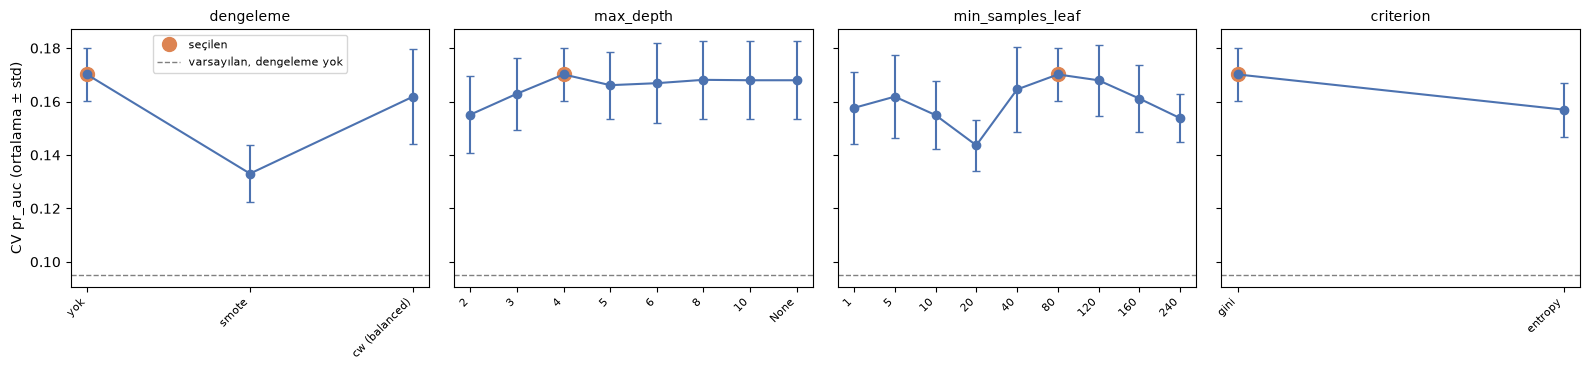

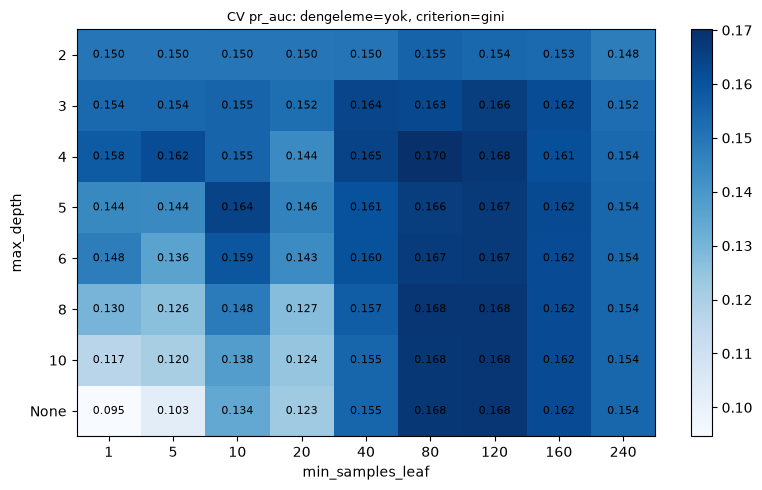

In [9]:
for col in HYPER:
    print(f"\n{col}:")
    show_param_table(one_at_a_time(full, col), col, full.loc[0, col])

fig, axes = plt.subplots(1, len(HYPER), figsize=(4 * len(HYPER), 3.8), sharey=True)
for ax, col in zip(axes, HYPER):
    sub = one_at_a_time(full, col)
    x = range(len(sub))
    ax.errorbar(x, sub["pr_auc_cv"], yerr=sub["pr_auc_std"], fmt="o-", color="#4C72B0", capsize=3)
    i = list(sub.index).index(full.loc[0, col])
    ax.plot(i, sub["pr_auc_cv"].iloc[i], "o", color="#DD8452", markersize=10, label="seçilen")
    ax.axhline(baseline_pr_auc, color="gray", linestyle="--", linewidth=1, label="varsayılan, dengeleme yok")
    ax.set_xticks(list(x))
    ax.set_xticklabels([s.replace("class_weight ", "cw ") for s in sub.index], rotation=45, ha="right", fontsize=8)
    ax.set_title(col, fontsize=10)
axes[0].set_ylabel(f"CV {MAIN_METRIC} (ortalama ± std)")
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIG_DIR / f"{MODEL_CODE}_param_effects.png", dpi=200)
plt.show()

# depth x min_samples_leaf, the other hyperparameters fixed at the best values
others = [c for c in HYPER if c not in ("max_depth", "min_samples_leaf")]
sub = full[(full[others] == full.loc[0, others]).all(axis=1)]
grid = (sub.pivot(index="max_depth", columns="min_samples_leaf", values="pr_auc_cv")
        .loc[GRID_ORDER["max_depth"], GRID_ORDER["min_samples_leaf"]])
fig, ax = plt.subplots(figsize=(1 + 0.8 * grid.shape[1], 1 + 0.5 * grid.shape[0]))
im = ax.imshow(grid.values.astype(float), cmap="Blues", aspect="auto")
ax.set_xticks(range(grid.shape[1]), grid.columns)
ax.set_yticks(range(grid.shape[0]), grid.index)
for (i, j), v in __import__("numpy").ndenumerate(grid.values.astype(float)):
    ax.text(j, i, f"{v:.3f}", ha="center", va="center", fontsize=8)
ax.set_xlabel("min_samples_leaf")
ax.set_ylabel("max_depth")
ax.set_title(f"CV {MAIN_METRIC}: {', '.join(f'{c}={full.loc[0, c]}' for c in others)}", fontsize=9)
fig.colorbar(im, ax=ax)
plt.tight_layout()
plt.savefig(FIG_DIR / f"{MODEL_CODE}_depth_leaf_heatmap.png", dpi=200)
plt.show()

### 3.5 Derinliğin etkisi (overfitting)

Her derinlik için, her dengeleme kolunda en iyi `min_samples_leaf` / `criterion` seçilerek eğitim ve CV skorları çizilir. Derinlik arttıkça eğitim skoru yükselir. CV skoru da yükselmiyorsa fazladan derinlik yalnızca ezberlemedir. Burada CV farklarının çoğu fold std'si içinde kalır; grafiği okurken bunu hesaba katın.

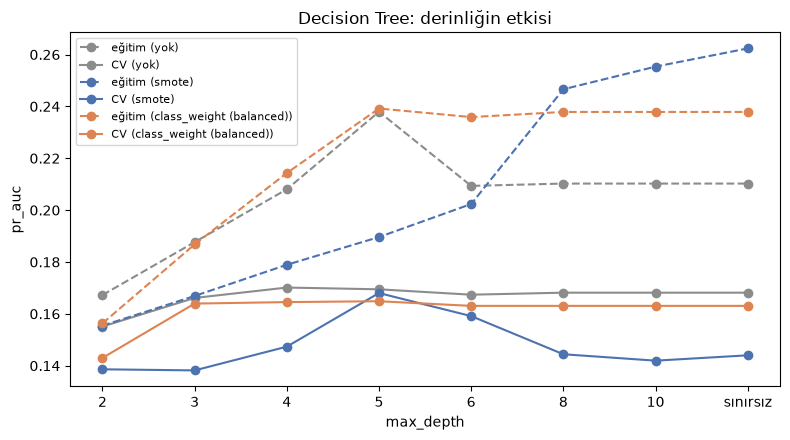

In [10]:
r = full.copy()
r["max_depth"] = r["max_depth"].replace("None", "sınırsız")
order = GRID_ORDER["max_depth"][:-1] + ["sınırsız"]

fig, ax = plt.subplots(figsize=(8, 4.5))
for bal, color in [("yok", "#8C8C8C"), ("smote", "#4C72B0"), ("class_weight (balanced)", "#DD8452")]:
    sub = (r[r["dengeleme"] == bal].sort_values("pr_auc_cv", ascending=False)
           .drop_duplicates("max_depth").set_index("max_depth").loc[order])
    ax.plot(order, sub["pr_auc_train"], "o--", color=color, label=f"eğitim ({bal})")
    ax.plot(order, sub["pr_auc_cv"], "o-", color=color, label=f"CV ({bal})")
ax.set_xlabel("max_depth")
ax.set_ylabel(MAIN_METRIC)
ax.set_title("Decision Tree: derinliğin etkisi")
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIG_DIR / f"{MODEL_CODE}_depth_overfitting.png", dpi=200)
plt.show()

### 3.6 Varsayılan model ve seçilen model yan yana

Seçilen model aynı pipeline ve aynı CV katlarıyla yeniden ölçülür (PR-AUC grid'deki değerle aynı çıkmalıdır).

In [11]:
tuned_label = f"Seçilen ({chosen_name}, derinlik {best_params['max_depth']}, yaprak {best_params['min_samples_leaf']}, {best_params['criterion']})"
compare = pd.concat([baseline, pd.DataFrame([cv_row(tuned_label, best)]).set_index("model")])
compare.round(3)

,pr_auc (CV ± std),recall,precision,f1,roc_auc,pr_auc_train
model,,,,,,
"Varsayılan, dengeleme yok",0.095 ± 0.010,0.144,0.126,0.134,0.525,1.000
Varsayılan + SMOTE,0.102 ± 0.013,0.238,0.141,0.177,0.552,1.000
"Seçilen (yok, derinlik 4, yaprak 80, gini)",0.170 ± 0.010,0.000,0.000,0.000,0.689,0.208


### 3.7 Karar

- **Başlangıç noktasına göre kazanç.** Varsayılan ağaç eğitim verisini tamamen ezberler (eğitim PR-AUC 1,00) ve CV PR-AUC'si 0,095 ± 0,010'dur; verideki inme oranına eşit rastgele tahmin düzeyi 0,087'dir. Ayarlanmış ağacın CV PR-AUC'si 0,170 ± 0,010, ROC-AUC'si 0,689'dur (varsayılan: 0,525). Yani ayar, ağacı rastgeleden belirgin biçimde ayırmıştır; bu fark fold std'sinin birkaç katıdır.
- **Seçilen model:** dengeleme yok, `max_depth=4`, `min_samples_leaf=80`, `criterion="gini"` (12 yaprak). Önceki aramada seçilen model SMOTE, derinlik 5, yaprak 80, entropy idi. Önceki seçim bu aramada da 0,168 ± 0,045 ile ilk 10 içindedir; yeni seçimden farkı 0,002'dir ve std'nin çok altındadır. Yeni seçim, daha basit olduğu (dengeleme adımı yok, daha az yaprak) ve fold'lar arası çok daha kararlı olduğu (std 0,010 / 0,045) için tercih edilir.
- **`min_samples_leaf`:** 80 artık aralığın içindedir: 120 ve 160 ile 240'ta skor düşüyor. 80 ile 120 arasındaki fark (0,170 / 0,168) std içindedir; bu yüzden "80 kesin en iyi" denmez, "geniş bir platonun (40-120) ortasındaki değer" denir.
- **`max_depth`:** 3'ten sonra skor 0,163 - 0,170 arasında düz kalır (hepsi std içinde). Büyük yaprak sınırı varken ağaç zaten derinleşemediği için 4'ten büyük derinlikler birbirinden ayırt edilemez; en küçük derinlik olan 4 seçildi.
- **Dengeleme:** Dengelemesiz kol en iyi PR-AUC'yi verdi (0,170), class_weight 0,162 ± 0,018, SMOTE 0,133 ± 0,011 (diğer ayarlar en iyi değerinde sabitken). Yok ile class_weight arasındaki fark std içindedir; SMOTE ise bu ayarlarda belirgin biçimde geridedir. PR-AUC eşikten bağımsız bir sıralama ölçüsü olduğu için dengelemesiz ağaç iyi sıralar; ancak 0,5 eşiğinde hiç inme tahmin etmez (recall 0). Bu yüzden karar eşiği bölüm 6'da ayrıca seçilir.
- **`criterion`:** gini 0,170 ± 0,010, entropy 0,157 ± 0,010; aynı yönde ama küçük bir fark.
- **Dürüstlük notu:** En iyi adayın bir standart sapması içinde 432 adayın 74'ü kalıyor. Yani seçim, tek bir "doğru" ayar değil, benzer sonuç veren bir bölgeden alınmış basit bir noktadır.

## 4. Feature engineering'in etkisi

Ortak pipeline 5 yeni özellik ekler (17 → 28 sütun). Ağaçlar gereksiz sütunları bölmede kullanmayarak kendileri eleyebilir; yine de türetilen özelliklerin katkı sağlayıp sağlamadığı en iyi parametrelerle kontrol edilir (bu deneyler `results.csv`'ye yazılmaz).

In [12]:
rows = {}
for fe in [True, False]:
    pipe = build_pipeline(DecisionTreeClassifier(random_state=RANDOM_STATE, **best_params),
                          balancing=chosen_balancing, feature_engineering=fe)
    res = cv_evaluate(pipe, X_train, y_train, model_name=f"{MODEL_NAME} (FE={fe})", save=False, verbose=False)
    rows["FE açık" if fe else "FE kapalı"] = res["summary"]["cv_mean"]
pd.DataFrame(rows).T.round(3)

metric,recall,precision,f1,specificity,roc_auc,pr_auc,accuracy
FE açık,0.0,0.0,0.0,1.0,0.689,0.170,0.913
FE kapalı,0.0,0.0,0.0,1.0,0.691,0.166,0.913


## 5. Final model: CV değerlendirmesi

Seçilen model ortak `cv_evaluate` ile değerlendirilir ve sonucu `results.csv`'ye **bir satır** olarak eklenir. Karşılaştırma notebook'u bu satırı kullanır. Eğitim ve CV skorları arasındaki fark (`gap`) overfitting göstergesidir.

In [13]:
cv_result = cv_evaluate(best, X_train, y_train, model_name=MODEL_NAME,
                        note=f"{chosen_name} + DT, GridSearch: {best_params}")

# Two CV PR-AUC numbers exist: the mean of the 5 fold scores (the table above, as in GridSearch)
# and one PR-AUC over all out-of-fold predictions pooled together (used for the threshold).
pooled = average_precision_score(cv_result["y"], cv_result["oof_score"])
print(f"CV PR-AUC, kat ortalaması: {cv_result['summary'].loc['pr_auc', 'cv_mean']:.4f} | "
      f"birleşik OOF: {pooled:.4f}")

===== Decision Tree: 5 katlı CV (eşik = 0.5) =====
Kat başına ortalama eğitim süresi: 0.01 sn

             train_mean  cv_mean  cv_std    gap
metric                                         
recall            0.000    0.000   0.000  0.000
precision         0.000    0.000   0.000  0.000
f1                0.000    0.000   0.000  0.000
specificity       1.000    1.000   0.000  0.000
roc_auc           0.750    0.689   0.018  0.060
pr_auc            0.208    0.170   0.010  0.038
accuracy          0.913    0.913   0.001 -0.000

Sonuç 'results.csv' dosyasına eklendi.
CV PR-AUC, kat ortalaması: 0.1701 | birleşik OOF: 0.1774


## 6. Eşik seçimi

Varsayılan eşik 0.5'tir, ama inmeyi kaçırmak yanlış alarmdan pahalı olduğu için eşik, **test setine bakılmadan** CV tahminleri (OOF) üzerinde seçilir: hedef recall'u (%80) en az yanlış alarmla sağlayan eşik.

Not: Decision Tree'nin skoru yaprağın inme oranıdır; ağacın yaprak sayısı kadar farklı skor olabilir. Bu yüzden eşik tablosunda bazı eşikler aynı sonucu verir.

===== Decision Tree: Eşik analizi (toplam 306 inme, 3521 kişi) =====
 threshold  caught  missed  false_alarms  recall  precision  specificity  false_alarms_per_1000
      0.05     256      50          1799   0.837      0.125        0.440                510.934
      0.10     178     128          1083   0.582      0.141        0.663                307.583
      0.15     102     204           431   0.333      0.191        0.866                122.408
      0.20      64     242           233   0.209      0.215        0.928                 66.174
      0.25      54     252           163   0.176      0.249        0.949                 46.294
      0.30      45     261           110   0.147      0.290        0.966                 31.241
      0.35       8     298            12   0.026      0.400        0.996                  3.408
      0.40       0     306             0   0.000      0.000        1.000                  0.000
      0.45       0     306             0   0.000      0.000        

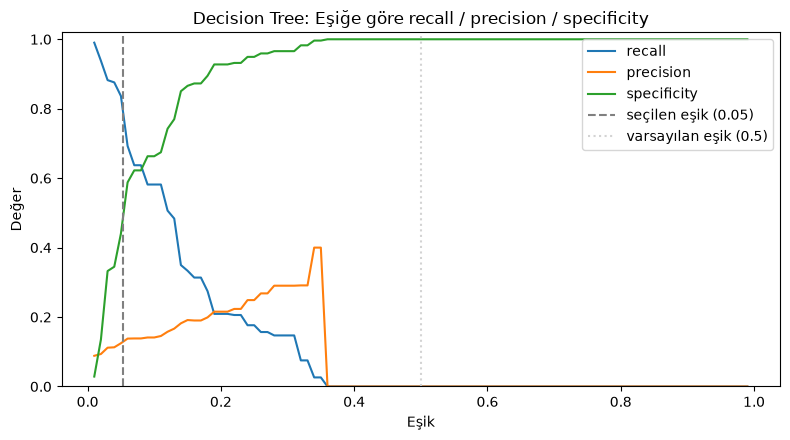

In [14]:
table, threshold = threshold_analysis(cv_result["y"], cv_result["oof_score"], model_name=MODEL_NAME)

## 7. Overfitting kontrolü: öğrenme eğrisi

Eğitim verisi büyüdükçe eğitim ve CV skorları birbirine yaklaşıyorsa model genelleşiyor demektir. Büyük ve kapanmayan bir fark overfitting, ikisinin birlikte düşük kalması underfitting gösterir.

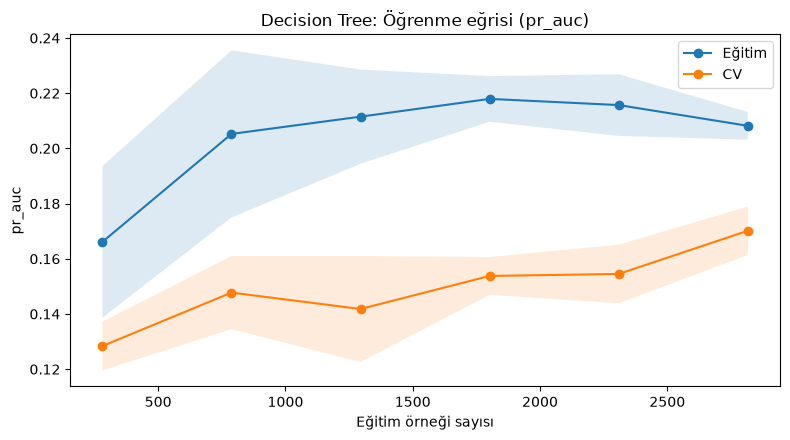

,train_size,train_mean,cv_mean,cv_std
0,281,0.166,0.128,0.009
1,788,0.205,0.148,0.013
2,1295,0.211,0.142,0.019
3,1802,0.218,0.154,0.007
4,2309,0.216,0.155,0.011
5,2816,0.208,0.170,0.009


In [15]:
lc = learning_curve_analysis(best, X_train, y_train, model_name=MODEL_NAME)
lc.round(3)

## 8. Test seti (yalnızca bir kez)

Final model tüm eğitim verisiyle yeniden eğitilir, seçilen eşikle test setinde değerlendirilir ve `models/` klasörüne kaydedilir.

===== Decision Tree: Test seti (eşik = 0.053) =====
70/77 inme yakalandı, 7 inme kaçırıldı, 447 yanlış alarm (881 kişi).

             cv_same_threshold   test  cv_minus_test
recall                   0.804  0.909         -0.105
precision                0.127  0.135         -0.008
f1                       0.220  0.236         -0.016
specificity              0.476  0.444          0.032
roc_auc                  0.686  0.742         -0.056
pr_auc                   0.177  0.208         -0.031
accuracy                 0.504  0.485          0.020


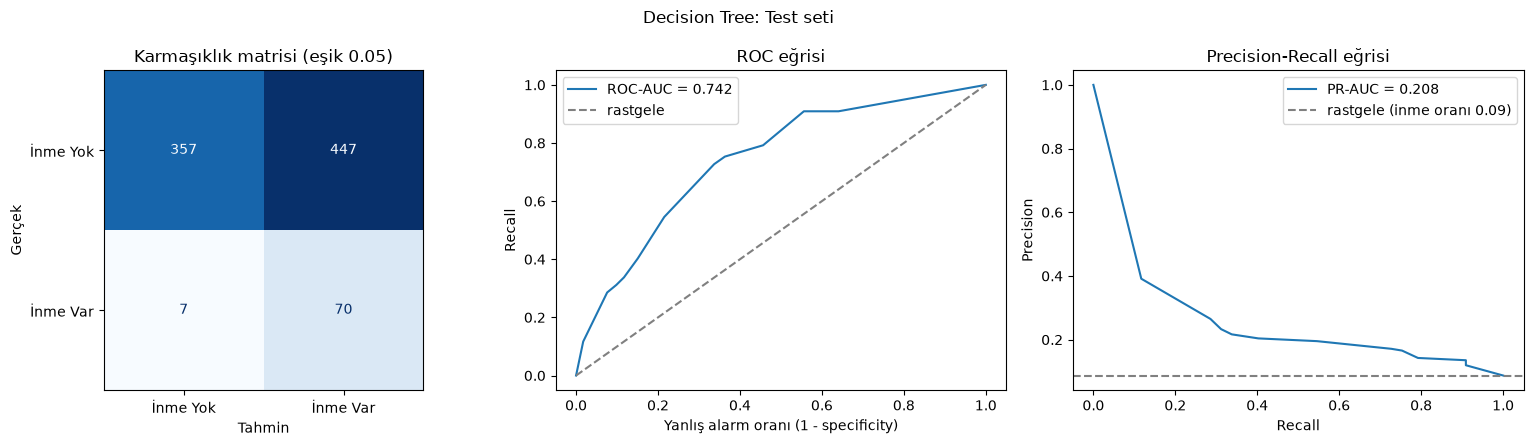

Model kaydedildi: models/dt.joblib


In [16]:
best.fit(X_train, y_train)
test_result = test_evaluate(best, X_test, y_test, threshold=threshold,
                            model_name=MODEL_NAME, cv_result=cv_result)

joblib.dump(best, MODEL_DIR / f"{MODEL_CODE}.joblib")
print(f"Model kaydedildi: models/{MODEL_CODE}.joblib")

## 9. Ağacın ilk seviyeleri

Final ağacın ilk 3 seviyesi. Her kutuda soru, o düğüme düşen eğitim verisinin yüzdesi (`samples`) ve sınıf oranları (`value` = [inme yok, inme var]) görünür. Renk koyulaştıkça düğüm daha saf olur (turuncu: inme yok, mavi: inme var). Seçilen modelde dengeleme yoktur, bu yüzden kökteki oranlar eğitim verisinin gerçek oranıdır (yaklaşık %9 inme).

Sütunlar ölçeklenmiş olduğu için eşikler ham değer değil, standart sapma cinsindendir (ör. `AGE <= 0.8`: ortalamanın 0.8 standart sapma üstü).

Derinlik: 4 | yaprak sayısı: 12


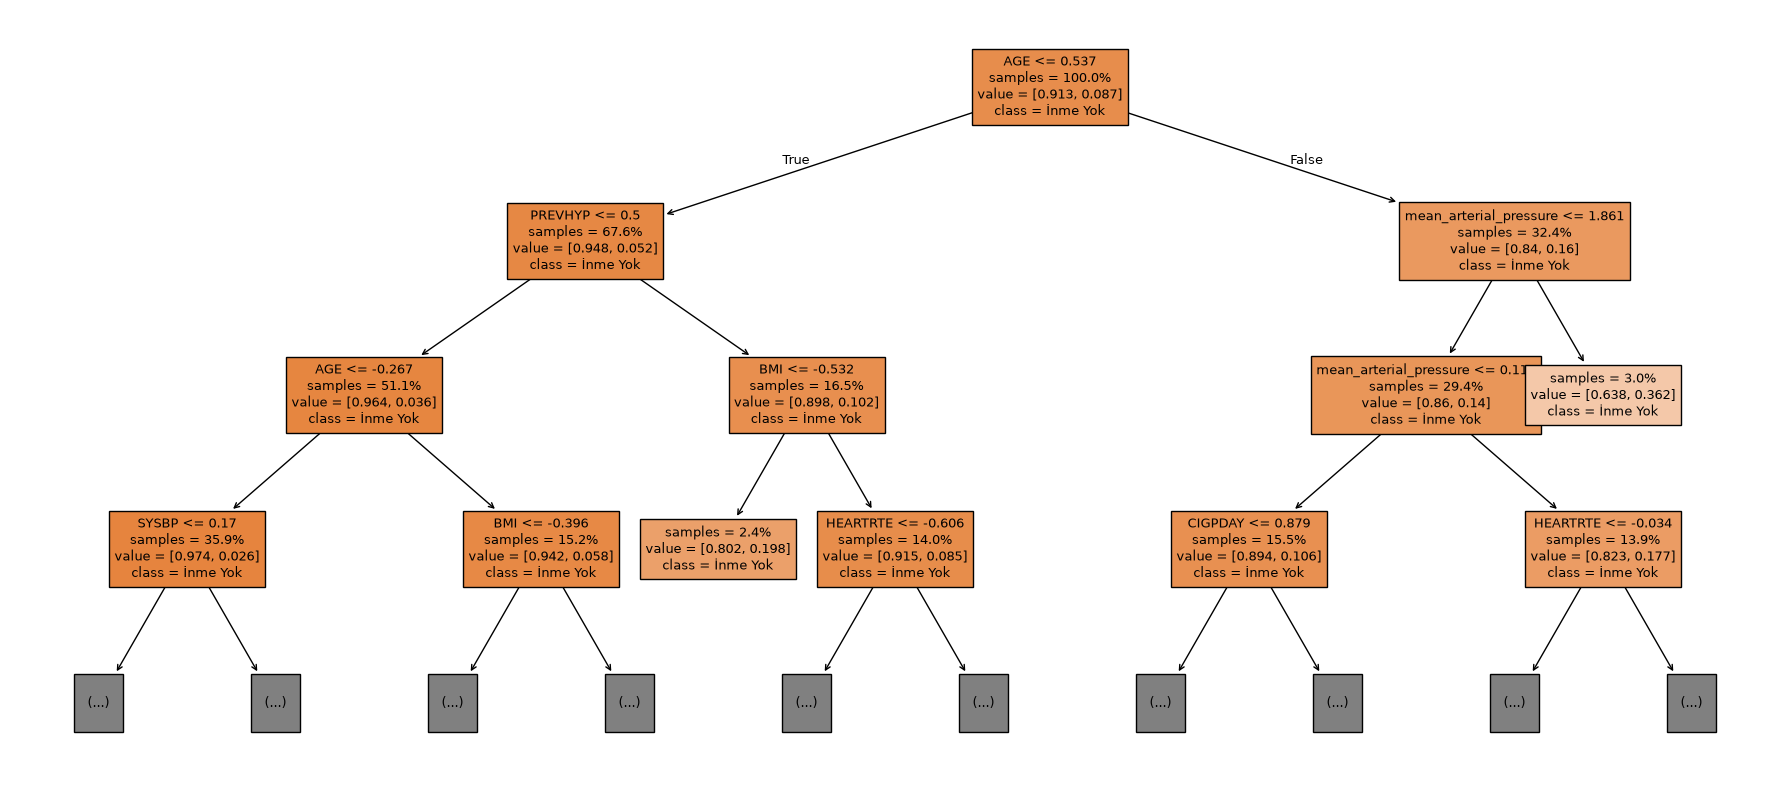

In [17]:
tree = best.named_steps["model"]
print("Derinlik:", tree.get_depth(), "| yaprak sayısı:", tree.get_n_leaves())

fig, ax = plt.subplots(figsize=(18, 8))
plot_tree(tree, max_depth=3, feature_names=list(tree.feature_names_in_), class_names=CLASS_NAMES,
          filled=True, impurity=False, proportion=True, fontsize=9, ax=ax)
plt.tight_layout()
plt.savefig(FIG_DIR / f"{MODEL_CODE}_tree.png", dpi=200)
plt.show()

## 10. XAI: modelin açıklanması

Decision Tree için ortak `explain()` fonksiyonu **TreeExplainer** kullanır: hızlıdır, tüm test verisi açıklanır. Fonksiyona aramanın kendisi değil, `best` (pipeline) verilir.

**Grafik okuma:** Bar grafiğinde çubuk uzunluğu önemi gösterir. Özet grafiğinde kırmızı = özelliğin değeri yüksek, mavi = düşük; nokta sağdaysa inme riskini artırıyor. LIME'da yeşil çubuklar "inme var" kararını destekleyen koşullardır. Buradaki LIME, test setinde en yüksek skoru alan hastayı gösterir (gerçek bir inme vakası ve yakalanmış, yani en kolay örnek); çalışma eşiğinde yakalanan ve kaçırılan tipik hastalar 10.1'de açıklanır.

===== Decision Tree: XAI Analizi =====


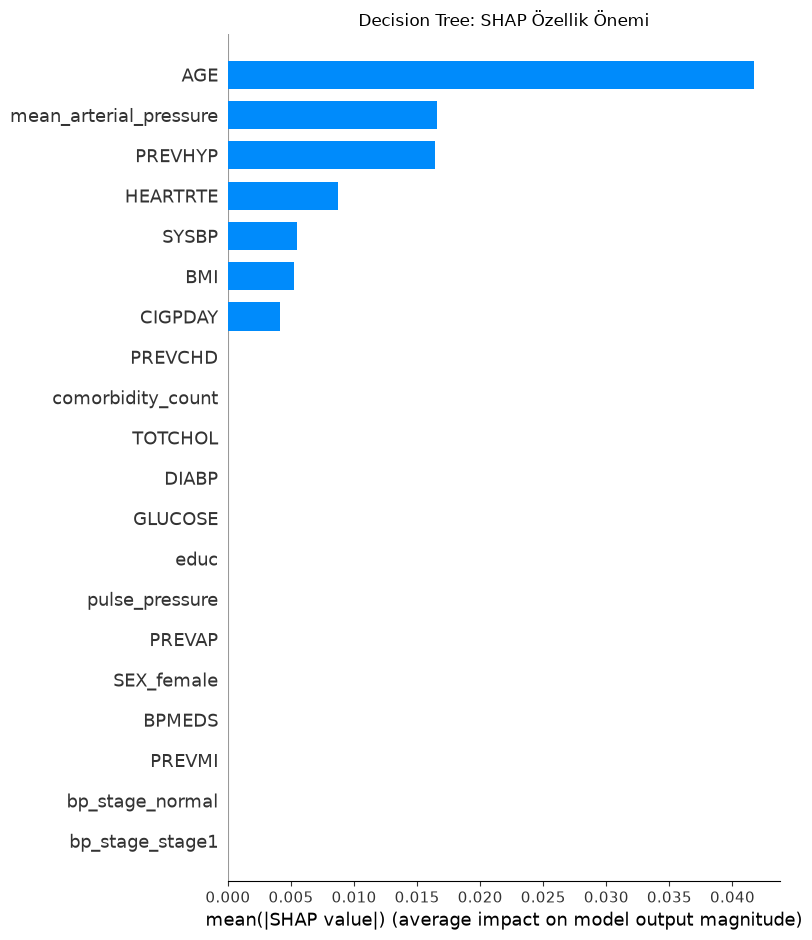

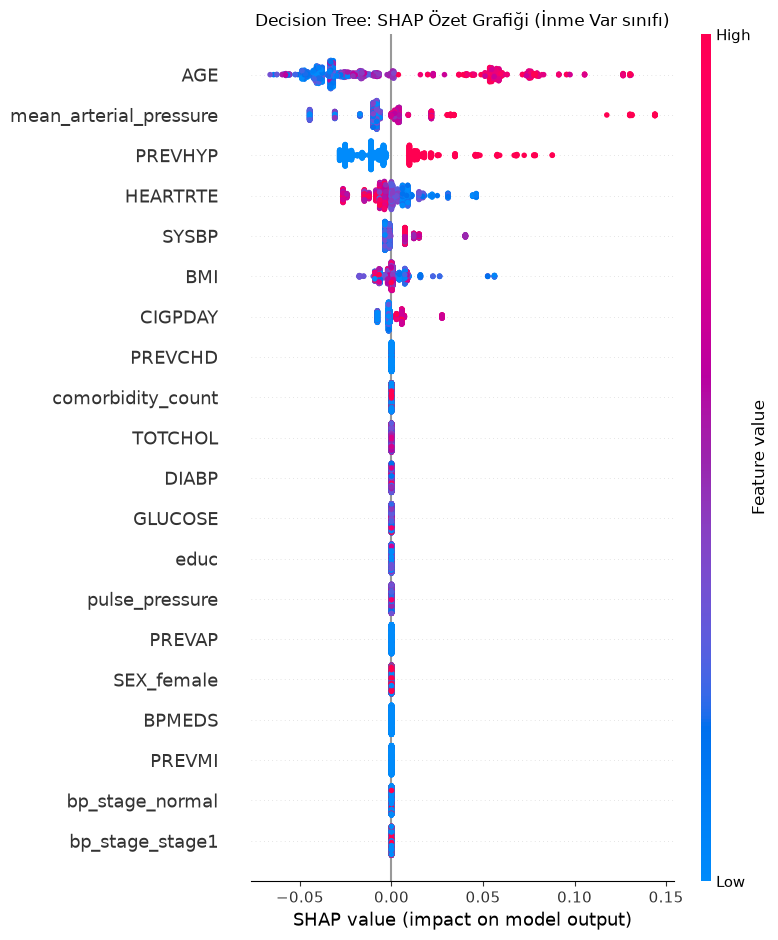


En önemli 5 özellik (SHAP):
               feature  mean_abs_shap
                   AGE       0.041683
mean_arterial_pressure       0.016578
               PREVHYP       0.016423
              HEARTRTE       0.008744
                 SYSBP       0.005500

[Decision Tree] Test hastası #75: model risk skoru = 0.362


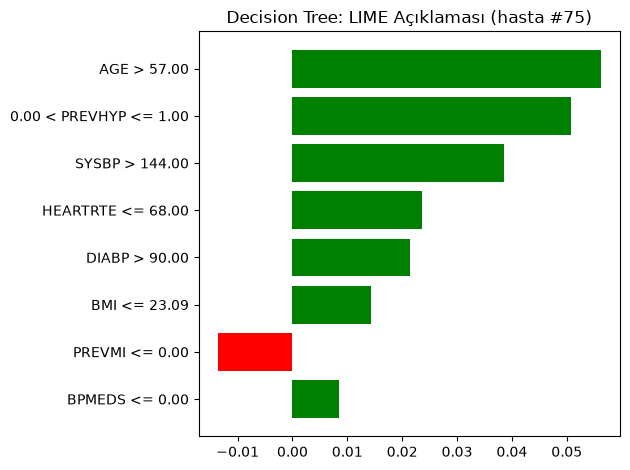

In [18]:
# explain() shows its plots in order: SHAP bar, SHAP summary, LIME. Each one is also saved to figures/.
_names = iter([f"{MODEL_CODE}_shap_bar.png", f"{MODEL_CODE}_shap_summary.png", f"{MODEL_CODE}_lime.png"])
_show = plt.show
def _save_and_show(*args, **kwargs):
    name = next(_names, None)
    if name:
        plt.gcf().savefig(FIG_DIR / name, dpi=200, bbox_inches="tight")
    _show(*args, **kwargs)

plt.show = _save_and_show
try:
    xai = explain(best, X_train, X_test, model_name=MODEL_NAME)
finally:
    plt.show = _show

In [19]:
xai["shap_importance"].head(10)

,feature,mean_abs_shap
0,AGE,0.041683
1,mean_arterial_pressure,0.016578
2,PREVHYP,0.016423
3,HEARTRTE,0.008744
4,SYSBP,0.005500
5,BMI,0.005235
6,CIGPDAY,0.004120
7,DIABP,0.000000
8,bmi_category_obese,0.000000
9,PREVMI,0.000000


### 10.1 Tek hasta açıklaması: yakalanan ve kaçırılan inme

Bölüm 10'daki LIME tek bir hastayı açıklıyordu: test setinde en yüksek skoru alan hasta (#75, skor 0,362). O hasta gerçekten inme geçirmişti ve yakalanmıştı; yani en kolay vakaydı. Kaçırılan hiçbir hasta açıklanmamıştı. "Model bu hastayı neden böyle yorumladı, bu hastayı neden kaçırdı?" sorusu için burada **çalışma eşiğinde** (bölüm 6, 0,053) iki gerçek inme vakası seçilir: yakalanan (doğru pozitif) ve kaçırılan (yanlış negatif) vakaların her biri için skoru grubun medyanına en yakın hasta. En uçtaki değil tipik hasta alınır ki seçim iyi görünen bir örneğe göre yapılmasın. Her hasta için ham değerleri, LIME açıklaması ve ağacın kendi karar yolu gösterilir. Hastalar test setindendir ama yalnızca açıklama içindir; model ya da eşik seçimini etkilemez.

In [20]:
# Typical caught and typical missed stroke patient of the test set at the working threshold (section 6):
# the patient whose score is closest to the median score of their group (not the extreme one).
score = test_result["score"]
y_arr = np.asarray(y_test)
caught_rows = np.where((y_arr == 1) & (score >= threshold))[0]
missed_rows = np.where((y_arr == 1) & (score < threshold))[0]

def typical(rows):
    return int(rows[np.argmin(np.abs(score[rows] - np.median(score[rows])))])

case_idx = {"caught": typical(caught_rows), "missed": typical(missed_rows)}

top = int(np.argmax(score))   # the patient LIME explained in section 10 (highest score)
print(f"Çalışma eşiği: {threshold:.3f} | test: {len(caught_rows)} inme yakalandı, {len(missed_rows)} kaçırıldı")
print(f"Bölüm 10'daki LIME hastası #{top}: gerçek inme = {bool(y_arr[top])}, skor {score[top]:.3f} -> "
      f"{'yakalanan' if y_arr[top] == 1 and score[top] >= threshold else 'yakalanan değil'}")
for key, i in case_idx.items():
    print(f"{key}: hasta #{i}, skor {score[i]:.3f}, eşik {threshold:.3f}")

patients = X_test.iloc[list(case_idx.values())].T
patients.columns = [f"{k} (#{i})" for k, i in case_idx.items()]
patients["test medyanı"] = X_test.median()
patients

Çalışma eşiği: 0.053 | test: 70 inme yakalandı, 7 kaçırıldı
Bölüm 10'daki LIME hastası #75: gerçek inme = True, skor 0.362 -> yakalanan
caught: hasta #79, skor 0.131, eşik 0.053
missed: hasta #138, skor 0.021, eşik 0.053


,caught (#79),missed (#138),test medyanı
AGE,64.00,46.00,49.0
TOTCHOL,262.00,211.00,234.0
SYSBP,147.00,120.00,128.0
DIABP,90.00,84.00,81.0
BMI,26.51,22.53,25.5
HEARTRTE,85.00,94.00,75.0
GLUCOSE,173.00,87.00,78.0
CIGPDAY,0.00,20.00,0.0
CURSMOKE,0.00,1.00,0.0
DIABETES,1.00,0.00,0.0


[Decision Tree] Test hastası #79: model risk skoru = 0.131


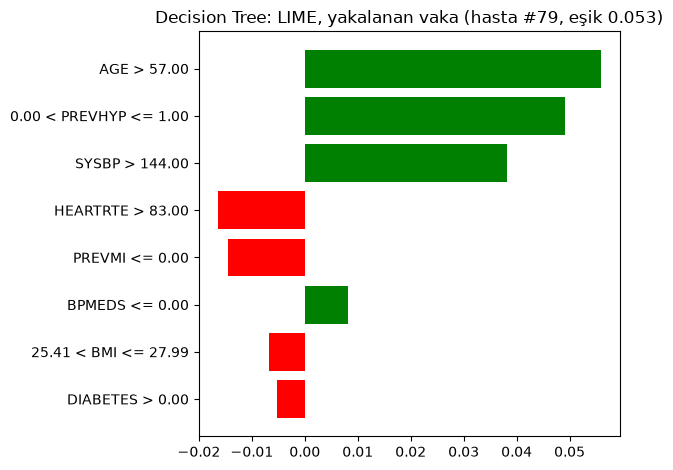

yakalanan vaka, LIME ağırlıkları (+ inme var kararını destekler):
  +0.056  AGE > 57.00
  +0.049  0.00 < PREVHYP <= 1.00
  +0.038  SYSBP > 144.00
  -0.016  HEARTRTE > 83.00
  -0.015  PREVMI <= 0.00
  +0.008  BPMEDS <= 0.00
  -0.007  25.41 < BMI <= 27.99
  -0.005  DIABETES > 0.00

[Decision Tree] Test hastası #138: model risk skoru = 0.021


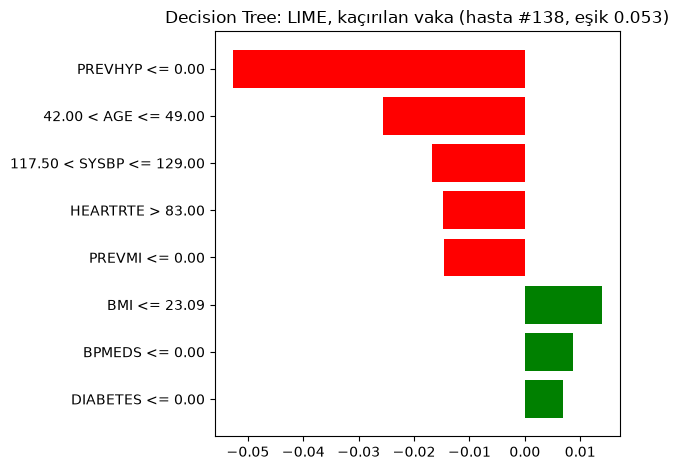

kaçırılan vaka, LIME ağırlıkları (+ inme var kararını destekler):
  -0.053  PREVHYP <= 0.00
  -0.026  42.00 < AGE <= 49.00
  -0.017  117.50 < SYSBP <= 129.00
  -0.015  HEARTRTE > 83.00
  -0.015  PREVMI <= 0.00
  +0.014  BMI <= 23.09
  +0.009  BPMEDS <= 0.00
  +0.007  DIABETES <= 0.00



In [21]:
for key, i in case_idx.items():
    label = "yakalanan vaka" if key == "caught" else "kaçırılan vaka"
    weights = lime_local(best, X_train, X_test, index=i, model_name=MODEL_NAME, save_prefix=FIG_DIR / MODEL_CODE,
                         save_name=f"lime_{key}", title=f"{MODEL_NAME}: LIME, {label} (hasta #{i}, eşik {threshold:.3f})")
    print(f"{label}, LIME ağırlıkları (+ inme var kararını destekler):")
    for condition, w in weights:
        print(f"  {w:+.3f}  {condition}")
    print()

In [22]:
# The tree explains itself: the questions asked on the way to the leaf (values are unscaled; bp_stage_* and binary columns are 0/1).
tree = best.named_steps["model"]
encoded = best[:-1].transform(X_test)
raw = best.named_steps["fe"].transform(X_test)
for key, i in case_idx.items():
    print(f"{key} (hasta #{i}):")
    nodes = tree.decision_path(encoded.iloc[[i]]).indices
    for n in nodes[:-1]:
        name = tree.feature_names_in_[tree.tree_.feature[n]]
        goes_left = encoded.iloc[i][name] <= tree.tree_.threshold[n]
        value = raw.iloc[i][name] if name in raw.columns else encoded.iloc[i][name]
        print(f"  {name} = {value:.2f}: eşik (ölçekli) {tree.tree_.threshold[n]:.2f}, {'<= (sol)' if goes_left else '> (sağ)'}")
    leaf = nodes[-1]
    print(f"  yaprak: eğitimde {int(tree.tree_.n_node_samples[leaf])} kişi, inme oranı {tree.tree_.value[leaf][0][1] / tree.tree_.value[leaf][0].sum():.3f}\n")

caught (hasta #79):
  AGE = 64.00: eşik (ölçekli) 0.54, > (sağ)
  mean_arterial_pressure = 109.00: eşik (ölçekli) 1.86, <= (sol)
  mean_arterial_pressure = 109.00: eşik (ölçekli) 0.12, > (sağ)
  HEARTRTE = 85.00: eşik (ölçekli) -0.03, > (sağ)
  yaprak: eğitimde 214 kişi, inme oranı 0.131

missed (hasta #138):
  AGE = 46.00: eşik (ölçekli) 0.54, <= (sol)
  PREVHYP = 0.00: eşik (ölçekli) 0.50, <= (sol)
  AGE = 46.00: eşik (ölçekli) -0.27, <= (sol)
  SYSBP = 120.00: eşik (ölçekli) 0.17, <= (sol)
  yaprak: eğitimde 1162 kişi, inme oranı 0.021



**Yorum.**

- **Yakalanan hasta (#79, skor 0,131, eşik 0,053):** 64 yaşında, hipertansiyon öyküsü ve diyabeti var, sistolik tansiyon 147, glukoz 173. Ağaç önce yaşa bakar (eşiğin üstünde), sonra ortalama arter basıncına ve nabza bakıp eğitimde 214 kişilik, inme oranı %13 olan yaprağa gönderir. LIME de aynı şeyi söyler: yaş > 57, hipertansiyon öyküsü ve sistolik tansiyon > 144 inme yönünde en güçlü üç koşuldur. Skor eşiğin yaklaşık 2,5 katıdır, karar sağlamdır.
- **Kaçırılan hasta (#138, skor 0,021, eşik 0,053):** 46 yaşında, hipertansiyon öyküsü yok, tansiyon 120/84, glukoz 87, BMI 22,5. Ağaç bu hastayı yaş eşiğinin altında ve hipertansiyon öyküsü olmayan 1162 kişilik yaprağa koyar; o yaprakta inme oranı yalnızca %2,1'dir. LIME'da "hipertansiyon öyküsü yok" (-0,053) ve "yaş 42-49" (-0,026) kararı en çok aşağı çeken koşullardır. Modelin kullandığı sinyallerin hiçbiri bu hastada yok.
- **Neden kaçtı?** Hasta modelin baktığı risk faktörleri açısından düşük riskli görünüyor (genç, tansiyonu normal, öyküsü yok). Günde 20 sigara içmesi ve nabzın 94 olması ağaçta bu yolda kullanılmıyor (12 yapraklı bir ağaç bütün sütunlara bakamaz), yani bu vaka kısmen ağacın küçüklüğü yüzünden kaçıyor; daha büyük bir model bu sütunlardan yararlanabilirdi (bunun işe yarayıp yaramayacağı burada denenmedi). Bu veriyle böyle bir hastayı yakalamak için eşiği, yaprağın inme oranının (%2,1) altına indirmek gerekirdi; bu da herkese (test setindeki 804 sağlıklı kişinin tamamına) alarm vermek demektir. Kaçırılan 7 vakanın hepsi aynı yaprakta olduğu için (skorların hepsi 0,021) bu açıklama onların tamamı için geçerlidir.
- **Dikkat:** LIME ağacın yerel bir yaklaşımıdır ve ağırlıkları küçük değişikliklerle oynayabilir; ağaç için asıl açıklama karar yoludur. İki açıklama burada aynı yönü gösteriyor.

### 10.2 Özellik çıkarma: en önemli özellikler olmadan model ne kadar iyi?

Soru: modelin dayandığı özellikler çıkarılırsa ne olur? Final yapılandırma (dengeleme yok, derinlik 4, yaprak 80, gini) aynı 5 katlı CV'de, seçilen özellikler olmadan yeniden eğitilir; hiperparametreler yeniden aranmaz. Çıkarma kodlamadan sonra, **türetilmiş sütunlarla birlikte** yapılır, çünkü feature engineering adımı bazı sütunları diğerlerinden türetir: `pulse_pressure`, `mean_arterial_pressure` ve `bp_stage` yalnızca `SYSBP` ile `DIABP`'den, `comorbidity_count` ise `DIABETES + PREVHYP + PREVCHD`'den gelir. Yalnız ham sütunu atmak bilgiyi türev sütunlardan geri getirir. "Tansiyon kümesi" `SYSBP`, `DIABP`, `pulse_pressure`, `mean_arterial_pressure` ve `bp_stage_*` sütunlarının hepsidir; "eşlik eden hastalık" ise `comorbidity_count` ile üç bileşenidir. Hipertansiyon öyküsü (`PREVHYP`) ayrı bir bilgi olduğu için tansiyon kümesi çıkarılınca kalır. Eşik her satırda bölüm 6'daki kuralla (OOF üzerinde %80 recall'u en az yanlış alarmla sağlayan eşik) yeniden seçilir; ağacın skoru kesikli olduğu için recall tam %80 yerine biraz üstünde çıkabilir. Rastgele düzey PR-AUC 0,087'dir.

In [23]:
import contextlib
import io

from sklearn.base import clone
from sklearn.preprocessing import FunctionTransformer
from metrics import compute_metrics

def drop_columns(X, cols):
    return X.drop(columns=cols)

# The FE step derives pulse_pressure / mean_arterial_pressure / bp_stage from SYSBP and DIABP, and comorbidity_count
# from DIABETES + PREVHYP + PREVCHD. Columns are dropped AFTER encoding, together with everything derived from them,
# so a removed feature cannot come back through a derived column.
encoded_cols = list(best.named_steps["encode"].get_feature_names_out())
BP_CLUSTER = ["SYSBP", "DIABP", "pulse_pressure", "mean_arterial_pressure"] + [c for c in encoded_cols if c.startswith("bp_stage_")]
COMORBIDITY = ["comorbidity_count", "DIABETES", "PREVHYP", "PREVCHD"]
REMOVALS = {
    "Hiçbiri (final model)": [],
    "AGE": ["AGE"],
    "AGE + comorbidity_count (bileşenler kalır)": ["AGE", "comorbidity_count"],
    "AGE + eşlik eden hastalık (count + 3 bileşeni)": ["AGE"] + COMORBIDITY,
    "Tansiyon kümesi": BP_CLUSTER,
    "AGE + tansiyon kümesi": ["AGE"] + BP_CLUSTER,
}

def pipeline_without(cols):
    pipe = clone(best)   # same balancing and hyperparameters as the final model, unfitted
    if cols:
        pipe.steps.insert(len(pipe.steps) - 1, ("drop", FunctionTransformer(drop_columns, kw_args={"cols": cols})))
    return pipe

rows = []
for label, cols in REMOVALS.items():
    res = cv_evaluate(pipeline_without(cols), X_train, y_train, model_name=label, save=False, verbose=False)
    with contextlib.redirect_stdout(io.StringIO()):
        _, thr = threshold_analysis(res["y"], res["oof_score"], plot=False)
    oof = compute_metrics(res["y"], res["oof_score"], thr)
    fp = int(((res["oof_score"] >= thr) & (res["y"] == 0)).sum())
    s = res["summary"]
    rows.append({"çıkarılan": label, "kalan sütun": len(encoded_cols) - len(cols),
                 "PR-AUC (CV ± std)": f"{s.loc['pr_auc', 'cv_mean']:.3f} ± {s.loc['pr_auc', 'cv_std']:.3f}",
                 "ROC-AUC": round(s.loc["roc_auc", "cv_mean"], 3),
                 "eşik (%80 recall)": round(thr, 3), "recall (OOF)": round(oof["recall"], 3),
                 "precision (OOF)": round(oof["precision"], 3),
                 "1000 kişide yanlış alarm": round(fp / len(res["y"]) * 1000)})
ablation = pd.DataFrame(rows).set_index("çıkarılan")
ablation

,kalan sütun,PR-AUC (CV ± std),ROC-AUC,eşik (%80 recall),recall (OOF),precision (OOF),1000 kişide yanlış alarm
çıkarılan,,,,,,,
Hiçbiri (final model),28,0.170 ± 0.010,0.689,0.053,0.804,0.127,479
AGE,27,0.161 ± 0.011,0.652,0.047,0.863,0.103,651
AGE + comorbidity_count (bileşenler kalır),26,0.150 ± 0.022,0.623,0.051,0.807,0.103,608
AGE + eşlik eden hastalık (count + 3 bileşeni),23,0.139 ± 0.021,0.594,0.041,0.820,0.096,670
Tansiyon kümesi,20,0.149 ± 0.007,0.680,0.053,0.804,0.127,479
AGE + tansiyon kümesi,19,0.131 ± 0.021,0.629,0.055,0.807,0.113,552


**Yorum.**

- **Hiçbir özellik tek başına modeli çökertmiyor.** `AGE` çıkarıldığında CV PR-AUC 0,170'ten 0,161'e iner (std 0,010; fark bir std'den küçük), ROC-AUC 0,689'dan 0,652'ye düşer. Yaşın taşıdığı bilginin bir kısmı hipertansiyon öyküsü ve tansiyon gibi korele sütunlardan geri alınıyor olabilir. Ama bedeli yanlış alarmda görünür: aynı %80 recall için 1000 kişide yanlış alarm 479'dan 651'e çıkar. Yaş, ağaca bilgiyi daha ucuza veriyor.
- **Küme olarak çıkarıldıklarında düşüş büyür:** tansiyon kümesi 0,149, AGE + eşlik eden hastalık 0,139, AGE + tansiyon kümesi 0,131 (ROC-AUC 0,59-0,63). Düşüş rastgele düzeye (0,087) inmez, çünkü geriye hâlâ yaş dışındaki sütunlar, nabız, glukoz, BMI, sigara kalıyor. Yani sinyal birkaç sütunda toplanmış değil, zayıf ve dağınık.
- **Türev sütunlar önemli:** yalnız `comorbidity_count` çıkarılınca (bileşenler kalır) PR-AUC 0,150, bileşenlerle birlikte çıkarılınca 0,139'dur. Aradaki 0,011 fark bileşenlerin sayıdaki bilginin bir kısmını geri taşıdığını gösterir; ama fark std (0,02) içindedir.
- **Tansiyon kümesi:** çıkarılınca PR-AUC 0,021 düşer (yaklaşık 2 std) ama yanlış alarm sayısı değişmez (479). Eşik, precision ve yanlış alarm aynı kaldığı için ağacın yaş + hipertansiyon öyküsü ağırlıklı yapısı büyük olasılıkla korunuyor; tansiyon sütunları yalnızca skorların sıralamasını inceltiyor (bu, ağaçlar karşılaştırılarak doğrulanmadı).
- **Sınırlar:** fark std'leri 0,01-0,02 olduğu için komşu satırlar (örneğin 0,139 ve 0,131) birbirinden ayırt edilemez. Çıkarılan özelliklerin yerini korele sütunlar aldığı için bu analiz "yaş olmadan model işe yarar" değil, "yaşın taşıdığı bilgi başka sütunlardan kısmen elde edilebiliyor" der.

## 11. Özet (rapor için)

### Neden Decision Tree?

- **Yorumlanabilirlik:** Decision Tree kararını "yaş eşiğin üstünde mi, eşlik eden hastalık var mı?" gibi bir soru zinciriyle verir. Ağaç çizilerek modelin bir hasta için hangi yoldan karara vardığı doğrudan okunabilir. Gerekçesiz kararın tıpta işe yaramadığı bu projede, kendi başına açıklanabilen bir model olarak seçildi.
- **Ön işleme ihtiyacı az:** Ağaçlar ölçeklemeden etkilenmez, sayısal ve ikili (0/1) sütunları birlikte kullanabilir, özellikler arasındaki etkileşimleri (ör. "yaşlı ve tansiyonu yüksek") kendiliğinden yakalar.
- **Ağaç ailesinin temel taşı:** Random Forest çok sayıda Decision Tree'nin birleşiminden oluşur. Tek ağacın sonuçları, Random Forest'ın tek ağaca göre ne kazandırdığını ölçmek için bir referans çizgisi olarak kullanıldı.
- **Bilinen zayıflığı:** Sınırlanmayan bir ağaç eğitim verisini ezberler (overfitting) ve verideki küçük değişikliklere karşı kararsızdır. Bu yüzden ağacın büyümesi hiperparametrelerle sınırlandı.


### Yöntem

- Hiperparametreler (`max_depth`, `min_samples_leaf`, `criterion`) ve dengeleme (yok, SMOTE, `class_weight="balanced"`) birlikte, 432 kombinasyonluk bir GridSearch ile, ekibin ortak 5 katlı CV bölmesi üzerinde arandı. En iyi model PR-AUC ile seçildi. Aramadan önce varsayılan ağaç aynı hat ve aynı katlarla ölçüldü; tüm adaylar `figures/dt_grid_results.csv` dosyasında.
- Bu özetteki CV PR-AUC değerleri, başka türlü belirtilmedikçe **5 katın skorlarının ortalamasıdır** (± katlar arası std). Eşik seçiminde kullanılan, tüm OOF tahminleri birleştirilerek hesaplanan PR-AUC ayrıdır (0,177).
- Seçilen model: **dengeleme yok, derinlik 4, yaprak başına en az 80 kişi, `gini`** (12 yaprak). Varsayılan ağaç CV PR-AUC 0,095 ± 0,010 iken seçilen ağaç 0,170 ± 0,010'dur. Derinlik, yaprak boyutu ve dengeleme seçenekleri arasındaki farkların çoğu fold std'si içindedir (432 adayın 74'ü en iyinin bir std'si içindedir); bu yüzden en basit ve kararlı nokta seçildi. SMOTE'lu önceki seçim (derinlik 5, yaprak 80) 0,168 ± 0,045'tir: ortalaması benzer, kararsızlığı çok daha büyüktür.
- Derinlik grafiği (`dt_depth_overfitting.png`) ve ısı haritası (`dt_depth_leaf_heatmap.png`): yaprak sınırı küçükken (1-20) derinlik arttıkça CV skoru düşer ve eğitim skoru yükselir (ezberleme); `min_samples_leaf` 80-120 iken derinlik 4'ten sonra CV skoru 0,166-0,168 arasında düz kalır. Yani derinliğin 5'ten sonra düştüğü söylenemez; 4'ten sonrasının CV'de ek bir faydası yoktur.
- Feature engineering ile türetilen özellikler CV PR-AUC'yi 0,166'dan 0,170'e çıkardı (fark std içinde); ortak pipeline'daki haliyle kullanıldı.

### Sonuçlar

| | CV (5 kat, eşik 0,5) | CV (OOF, seçilen eşik 0,053) | Test (881 kişi, eşik 0,053) |
|---|---|---|---|
| Recall | 0,000 | 0,804 | 0,909 |
| Precision | 0,000 | 0,127 | 0,135 |
| F1 | 0,000 | 0,220 | 0,236 |
| Specificity | 1,000 | 0,476 | 0,444 |
| ROC-AUC | 0,689 ± 0,018 | | 0,742 |
| PR-AUC | 0,170 ± 0,010 (kat ort.) | 0,177 (birleşik OOF) | 0,208 |

- Ağaç 0,5 eşiğinde hiç inme tahmini yapmaz (yaprakların en yüksek inme oranı 0,5'in altındadır), bu yüzden o sütunda recall ve precision 0'dır. Eşik, test setine bakılmadan CV tahminleri üzerinde, vakaların en az %80'ini en az yanlış alarmla yakalayacak şekilde 0,053 seçildi.
- Test setinde 77 inme vakasının **70'i yakalandı, 7'si kaçırıldı**; bunun bedeli 804 sağlıklı kişiden 447'sine verilen yanlış alarmdır. Test setinde yalnızca 77 vaka olduğu için bu sayılar gürültülüdür; testin CV'den yüksek çıkması modelin CV'den iyi olduğunu göstermez.
- Eğitim ile CV PR-AUC arasındaki fark 0,038'dir (0,208 / 0,170) ve overfitting uyarısı çıkmamıştır. Öğrenme eğrisinde eğitim skoru 0,166'dan 0,208'e, CV skoru 0,128'den 0,170'e çıkar; ikisi de düşük ve CV skoru veri arttıkça hâlâ yükselmektedir. Model ezber yapmıyor, ama sinyal zayıf: ağaç küçük ve basit, yeni veri eklemek CV skorunu biraz daha yükseltebilir.

### Model neye dayanıyor?

- Ağacın ilk bölünmesi **yaşa** göredir; genç grupta ikinci soru **hipertansiyon öyküsü** (PREVHYP), yaşlı grupta **ortalama arter basıncıdır**.
- SHAP'a göre en önemli özellikler: yaş (açık ara), ortalama arter basıncı, hipertansiyon öyküsü, nabız ve sistolik tansiyon. Bunlar bilinen inme risk faktörleriyle uyumludur.
- Tek hasta (10.1, çalışma eşiği 0,053): yakalanan hasta (#79, 64 yaş, hipertansiyon öyküsü, sistolik 147) skoru 0,131 olan, eğitimde inme oranı %13 olan yaprağa düşer. Kaçırılan hasta (#138, 46 yaş, hipertansiyon öyküsü yok, tansiyon 120/84) inme oranı %2,1 olan 1162 kişilik yaprağa düşer; kaçırılan 7 vakanın tamamı bu yapraktadır. Bu vakalar modelin baktığı risk faktörlerini taşımadığı için ancak eşik herkese alarm verecek kadar düşürülürse yakalanır.
- Özellik çıkarma (10.2, aynı final ayarlar, türev sütunlar dahil): CV PR-AUC 0,170 ± 0,010'dan `AGE` çıkarılınca 0,161 ± 0,011'e, tansiyon kümesi çıkarılınca 0,149 ± 0,007'ye, `AGE` + eşlik eden hastalık çıkarılınca 0,139 ± 0,021'e, `AGE` + tansiyon kümesi çıkarılınca 0,131 ± 0,021'e iner (rastgele düzey 0,087). Tek bir özellik modeli çökertmez ama aynı %80 recall için 1000 kişide yanlış alarm, yaş çıkınca 479'dan 651'e çıkar. Birkaç özellik birlikte çıkarıldığında model hâlâ rastgeleden iyidir; sinyal birkaç sütunda toplanmamış, zayıf ve dağınıktır. Komşu satırların farkı fold std'si içindedir.

### Değerlendirme

- Decision Tree rastgele tahminden iyidir (CV PR-AUC 0,17; rastgele düzey 0,09), ancak tek başına sınırlı bir modeldir: vakaların çoğunu yakalamak için çok sayıda yanlış alarm verir (precision %13).
- Bunun nedeni, kararın 12 yapraklı kaba bir kural zincirine indirgenmesi ve tek ağacın küçük veri değişikliklerine duyarlı olmasıdır. Random Forest, çok sayıda ağacın oylarını birleştirerek bu iki sorunu azaltmayı hedefler.